In [3]:
%load_ext autoreload
%autoreload 2

import numpy as np
import matplotlib.pyplot as plt
import utils as ut

To validate my code, I run simulations at $T_{\text{BKT}}$ and observe the expected behaviour

$$
S(k)\propto k^{-7/4}
$$,

where $k:=|\vec k|$ is the magnitude of the wavevector and $S(k)$ is the radially-averaged structure factor.

In [4]:
def structure_factor(lattice):
    N = lattice.size

    spin_x = np.cos(lattice)
    spin_y = np.sin(lattice)

    spin_x_k = np.fft.fft2(spin_x)
    spin_y_k = np.fft.fft2(spin_y)

    S_k = (np.abs(spin_x_k)**2 + np.abs(spin_y_k)**2) / N

    return np.fft.fftshift(S_k)

def radial_average(S_k):
    L = S_k.shape[0]

    # wavevector values along each axis
    k = 2 * np.pi * np.fft.fftshift(np.fft.fftfreq(L))
    kx, ky = np.meshgrid(k, k)

    # magnitude of wavevector at every pixel
    k_mag = np.sqrt(kx**2 + ky**2)

    # width of one radial bin
    dk = 2 * np.pi / L

    k_values = np.arange(0, np.pi, dk)
    S_radial = []

    for k0 in k_values:
        mask = (k_mag >= k0) & (k_mag < k0 + dk)
        S_radial.append(np.mean(S_k[mask]))

    return k_values, np.array(S_radial)

# $L=100$ for 100 runs

In [5]:
L = 100 # system is a square lattice of L^2 spins

# hamiltonian parameters
H = 0. # H = mu_s * B / J
phi = 0 # angle of magnetic field
T = 0.8935 # critical temperature T_BKT for this validation

# metropolis parameters
delta = np.pi / 4 # the maximum a spin can rotate in one iteration
num_sweeps = 10000 # number of monte carlo sweeps = num_sweeps * N monte carlo iterations
# 5000 sweeps = ~3 seconds

# validation parameters
runs = 100

In [4]:
N = L**2
steps = N * num_sweeps

S_radials = []

for run in range(runs):
    lattice = ut.generate_lattice(L)
    energy = ut.get_energy(lattice, H, phi)
    final_lattice, _, _, _, _ = ut.metropolis(lattice, steps, T, H, phi, energy, delta)

    S_k = structure_factor(final_lattice)
    k, S_radial = radial_average(S_k)

    S_radials.append(S_radial)

mean_S_radial = np.mean(S_radials, axis=0)

Gradient = -1.7727363245721917


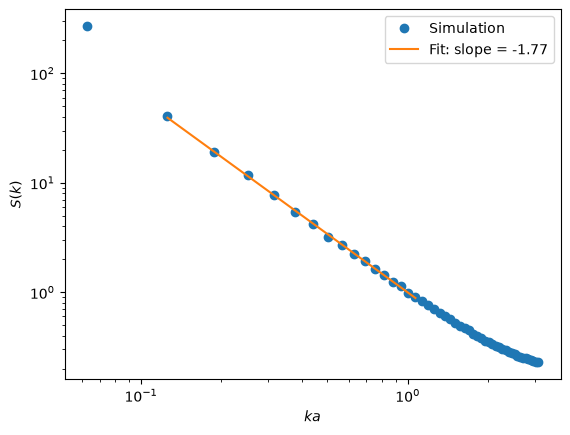

In [ ]:
# fit low-k data to a best-fit line and compute its gradient
mask = (k > 0.1) & (k < 1.1)
slope, intercept = np.polyfit(np.log(k[mask]), np.log(mean_S_radial[mask]), 1)
print("Gradient =", slope)


# plot best-fit line with data points
plt.loglog(k[1:], mean_S_radial[1:], 'o', label="Simulation")

fit = np.exp(intercept) * k[mask]**slope
plt.loglog(k[mask], fit, label=f"Fit: slope = {slope:.2f}")

plt.xlabel(r"$ka$")
plt.ylabel(r"$S(k)$")
plt.legend()
plt.show()

The gradient is quite close to the expected value of $-7/4\approx -1.75$, but I'm cautious about interpreting this as a big success as it is known that it is difficult to reproduce these laws through Monte Carlo simulations of the XY model (Janke, 1996: https://arxiv.org/pdf/hep-lat/9609045)

# $L=200$ for 20 runs

In [6]:
L = 200
runs = 20

S_radials_2 = []
steps = L**2 * num_sweeps

for run in range(runs):
    lattice = ut.generate_lattice(L)
    energy = ut.get_energy(lattice, H, phi)
    final_lattice, _, _, _, _ = ut.metropolis(lattice, steps, T, H, phi, energy, delta)

    S_k = structure_factor(final_lattice)
    k, S_radial = radial_average(S_k)

    S_radials_2.append(S_radial)

mean_S_radial_2 = np.mean(S_radials_2, axis=0)

Gradient = -2.1012690855710274


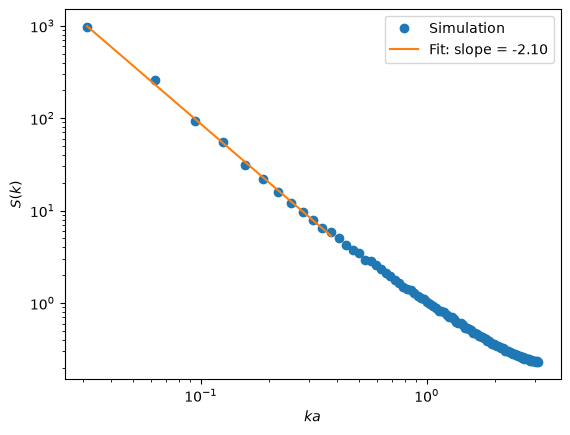

In [13]:
# fit low-k data to a best-fit line and compute its gradient
mask = (k > 0.0) & (k < 0.4)
slope, intercept = np.polyfit(np.log(k[mask]), np.log(mean_S_radial_2[mask]), 1)
print("Gradient =", slope)


# plot best-fit line with data points
plt.loglog(k[1:], mean_S_radial_2[1:], 'o', label="Simulation")

fit = np.exp(intercept) * k[mask]**slope
plt.loglog(k[mask], fit, label=f"Fit: slope = {slope:.2f}")

plt.xlabel(r"$ka$")
plt.ylabel(r"$S(k)$")
plt.legend()
plt.show()

Although the lattice is larger and thus should tend towards the theoretical value (which assumes infinite lattice), the best-fit slope is $~-2$. In general, through other experiments with other lattice sizes, I generally observed a slope of $~-2$.